# 01 · Segmentación de agua con U-Net en imágenes NISAR de lluvias en el Perú

Imágenes de radar **NISAR** (banda L, grilla de 5 m) tomadas el día de una lluvia o en las horas siguientes en **Lima
(Lima Metropolitana y Callao), Tumbes y Arequipa**. Para cada píxel: ¿hay agua en superficie? Interesa tanto la inundación
como el **agua que se queda empozada** en calles, baipases y terrenos después de la lluvia (sección 6.2).

1. Datos · 2. Preprocesamiento · 3. Normalización · 4. Modelo · 5. Resultados · 6. Aplicación externa (Tumbes y Arequipa) · 7. Conclusiones

## 1. Datos

Imágenes NISAR **RSLC** (`.h5`, nivel 1) que baja `descarga_datos.ipynb`: el recorte de cada ciudad, con los números
complejos originales sin procesar, una carpeta por ciudad. Una pasada puede venir en dos archivos (**cuadros**) seguidos de la
misma órbita; en Lima la pista 083 necesita el cuadro 095 (sur) y el 094 (norte), y la 003 el 171 y el 172. Cada pasada se
identifica como `ciudad_fecha`. En cada ciudad hay días de lluvia y **días secos de la misma pista** (misma órbita, hora y
ángulo de vista), que sirven solo de referencia y no se usan para entrenar.

| Rol | Escenas |
|---|---|
| train | 3 lluvias de Lima vistas por la pista 083 a las 18:25: 14 ene (solo Lima Sur y Centro: ese día no hay cuadro norte), 18 ago y 5 oct 2026 |
| validación | la llovizna del 22 oct en Lima, vista por la otra pista (003) el 24 oct a las 05:58 |
| externa | Tumbes (lluvia del 23 oct, pasada del 24 oct 2026) y Arequipa (lluvia del 16 feb, pasada del 17 feb 2026): otras ciudades, otras pistas; y Lima 5 nov si ya está publicada |

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio, h5py
from scipy import ndimage

secos = {"lima": ["20251103", "20251127", "20260701", "20260713", "20260725", "20260830", "20261017",
                  "20251029", "20260825", "20260906", "20260930", "20261012"],
         "tumbes": ["20260720", "20260813"], "arequipa": ["20260629", "20260711"]}
train, val = ["lima_2026-01-14", "lima_2026-08-18", "lima_2026-10-05"], ["lima_2026-10-24"]
h5s = sorted(Path("Data/crudos_nisar").glob("*/*.h5"))
archivos = pd.DataFrame({"h5": h5s, "ciudad": [h.parent.name for h in h5s], "pista": [h.name[21:26] for h in h5s],
                         "cuadro": [h.name[27:30] for h in h5s], "fecha": [h.name[43:51] for h in h5s],
                         "hora_local": [f"{int(h.name[52:54]) - 5:02d}:{h.name[54:56]}" for h in h5s]})
escenas = archivos.groupby(["ciudad", "pista", "fecha"]).agg(h5=("h5", list), cuadros=("cuadro", "+".join),
                                                              hora_local=("hora_local", "first")).reset_index()
escenas["clave"] = escenas.ciudad + "_" + escenas.fecha.str[:4] + "-" + escenas.fecha.str[4:6] + "-" + escenas.fecha.str[6:]
escenas["dia"] = ["seco" if f in secos[c] else "lluvia" for c, f in zip(escenas.ciudad, escenas.fecha)]
escenas["rol"] = np.select([escenas.dia == "seco", escenas.clave.isin(train), escenas.clave.isin(val)],
                           ["referencia", "train", "val"], "externa")
escenas[["clave", "pista", "cuadros", "hora_local", "dia", "rol"]]

,clave,pista,cuadros,hora_local,dia,rol
0,arequipa_2026-02-17,046_A,169,05:32,lluvia,externa
1,arequipa_2026-06-29,046_A,169,05:32,seco,referencia
2,arequipa_2026-07-11,046_A,169,05:32,seco,referencia
3,lima_2025-10-29,003_A,171,05:58,seco,referencia
4,lima_2026-08-25,003_A,171+172,05:58,seco,referencia
5,lima_2026-09-06,003_A,171+172,05:58,seco,referencia
6,lima_2026-09-30,003_A,171+172,05:58,seco,referencia
7,lima_2026-10-12,003_A,171+172,05:58,seco,referencia
8,lima_2026-10-24,003_A,171+172,05:58,lluvia,val
9,lima_2025-11-03,083_D,095,18:25,seco,referencia


## 2. Preprocesamiento

| Paso | Qué hace |
|---|---|
| 2.1 Grilla | una grilla UTM de 5 m por ciudad y el DEM Copernicus de 30 m como altura sobre el elipsoide |
| 2.2 Geocodificación | cada RSLC (geometría de radar) se lleva a la grilla: intensidad HH en dB |
| 2.3 Pendiente y WorldCover | terreno plano y agua permanente de referencia |
| 2.4 Etiqueta | máscara de agua del mismo día |
| 2.5 Validación de datos | ¿sirve cada escena para segmentar agua? |
| 2.6 Parches | recortes de 256 × 256 para la U-Net |

### 2.1 Grilla y DEM

Cada ciudad tiene su caja y su huso UTM (17 S Tumbes, 18 S Lima, 19 S Arequipa). La de Lima va de Ventanilla, Puente Piedra
y Carabayllo hasta Lurín, y de La Punta hasta Chaclacayo (unos 2 200 km²). El DEM Copernicus da altura sobre el geoide; se le
suma la ondulación del geoide EGM2008 (24 m en Lima, 8 m en Tumbes, 40 m en Arequipa) porque la geolocalización de NISAR usa
altura sobre el elipsoide.

In [2]:
import requests, pyproj
from functools import lru_cache
from pyproj import Transformer
from rasterio.merge import merge
from rasterio.warp import reproject, Resampling
from rasterio.transform import from_origin, rowcol

pyproj.network.set_network_enabled(True)
cajas = {"lima": (-77.18, -12.30, -76.75, -11.80), "tumbes": (-80.50, -3.62, -80.22, -3.45),
         "arequipa": (-71.66, -16.47, -71.46, -16.28)}
epsg = {"lima": 32718, "tumbes": 32717, "arequipa": 32719}
geoide = Transformer.from_crs("EPSG:4326+3855", "EPSG:4979", always_xy=True)


@lru_cache
def mosaico(coleccion, ciudad):
    o, s, e, n = cajas[ciudad]
    caja = [o - 0.02, s - 0.02, e + 0.02, n + 0.02]
    fecha = {"datetime": "2021-01-01T00:00:00Z/2021-12-31T23:59:59Z"} if coleccion == "esa-worldcover" else {}
    items = requests.post("https://planetarycomputer.microsoft.com/api/stac/v1/search",
                          json={"collections": [coleccion], "bbox": caja, **fecha}).json()["features"]
    token = requests.get(f"https://planetarycomputer.microsoft.com/api/sas/v1/token/{coleccion}").json()["token"]
    capa = "map" if coleccion == "esa-worldcover" else "data"
    arr, tr = merge([rasterio.open(i["assets"][capa]["href"] + "?" + token) for i in items], bounds=caja)
    return arr[0], tr


def en_grilla(coleccion, ciudad, metodo):
    arr, tr = mosaico(coleccion, ciudad)
    p = grillas[ciudad]
    out = np.zeros((p["height"], p["width"]), arr.dtype)
    reproject(arr, out, src_transform=tr, src_crs="EPSG:4326", dst_transform=p["transform"], dst_crs=p["crs"], resampling=metodo)
    return out


grillas, filas = {}, []
for ciudad, (o, s, e, n) in cajas.items():
    xs, ys = Transformer.from_crs("EPSG:4326", f"EPSG:{epsg[ciudad]}", always_xy=True).transform([o, e, o, e], [s, s, n, n])
    x0, x1, y0, y1 = 5 * np.floor(min(xs) / 5), 5 * np.ceil(max(xs) / 5), 5 * np.floor(min(ys) / 5), 5 * np.ceil(max(ys) / 5)
    grillas[ciudad] = dict(driver="GTiff", height=int((y1 - y0) / 5), width=int((x1 - x0) / 5), count=1, dtype="float32",
                           crs=f"EPSG:{epsg[ciudad]}", transform=from_origin(x0, y1, 5, 5), compress="deflate", predictor=3,
                           tiled=True, nodata=np.nan, BIGTIFF="IF_SAFER")
    carpeta = Path(f"Data/procesado/nisar/{ciudad}")
    carpeta.mkdir(parents=True, exist_ok=True)
    n_geoide = geoide.transform((o + e) / 2, (s + n) / 2, 0)[2]
    if not (carpeta / "dem.tif").exists():
        with rasterio.open(carpeta / "dem.tif", "w", **grillas[ciudad]) as f:
            f.write(en_grilla("cop-dem-glo-30", ciudad, Resampling.bilinear).astype("float32") + n_geoide, 1)
    dem = rasterio.open(carpeta / "dem.tif").read(1)
    filas.append({"ciudad": ciudad, "EPSG": epsg[ciudad], "filas": dem.shape[0], "columnas": dem.shape[1],
                  "km²": dem.size * 25 / 1e6, "geoide_m": n_geoide, "altura_min_m": dem.min(), "altura_max_m": dem.max()})
pd.DataFrame(filas).round(1)

,ciudad,EPSG,filas,columnas,km²,geoide_m,altura_min_m,altura_max_m
0,lima,32718,11132,9445,2628.5,24.8,18.400000,2905.500000
1,tumbes,32717,3764,6224,585.7,8.4,5.800000,122.500000
2,arequipa,32719,4262,4329,461.3,39.7,1998.900024,3686.699951


### 2.2 Geocodificación

Una RSLC guarda números complejos en **geometría de radar** (filas = tiempo de vuelo, columnas = distancia al satélite). El
archivo trae, para una grilla de puntos de la imagen, su posición en el mapa a 20 alturas (−500 a 9000 m). Para cada punto de
la grilla de 5 m:

1. se interpola esa grilla en las dos alturas que encierran el terreno de la ciudad (0-500 m en Tumbes, 0-2000 m en Lima,
   1500-4000 m en Arequipa) y se elige entre ambas con la altura del DEM;
2. con esa posición (fila, columna) se lee el valor complejo de HH por interpolación bilineal.

Si la pasada viene en dos cuadros, cada uno llena la parte de la ciudad que cubre. Se guarda la intensidad **HH en dB**
(`hh_fecha.tif`) y, para la pista 083 de Lima, el valor complejo de Lima Sur (`slc_fecha.npy`, coherencia de 6.3).

In [3]:
from scipy.interpolate import LinearNDInterpolator


def a_grilla(h5s, ciudad):
    p, (o, s, e, n) = grillas[ciudad], cajas[ciudad]
    dem = rasterio.open(f"Data/procesado/nisar/{ciudad}/dem.tif").read(1)
    alto, ancho = dem.shape
    cc, ff = np.meshgrid(np.arange(0, ancho, 10), np.arange(0, alto, 10))
    lon, lat = Transformer.from_crs(p["crs"], "EPSG:4326", always_xy=True).transform(p["transform"].c + (cc + 0.5) * 5,
                                                                                      p["transform"].f - (ff + 0.5) * 5)
    fi, fj = np.meshgrid(np.arange(alto, dtype="float32") / 10, np.arange(ancho, dtype="float32") / 10, indexing="ij")
    hh, compleja = np.full(dem.shape, np.nan, "float32"), np.full(dem.shape, np.nan, "complex64")
    for h5 in h5s:
        with h5py.File(h5) as f:
            g, sw = f["science/LSAR/RSLC/metadata/geolocationGrid"], f["science/LSAR/RSLC/swaths"]
            t, r = sw["zeroDopplerTime"][()], sw["frequencyA/slantRange"][()]
            ta, ra = np.meshgrid((g["zeroDopplerTime"][()] - t[0]) / (t[1] - t[0]), (g["slantRange"][()] - r[0]) / (r[1] - r[0]),
                                 indexing="ij")
            alturas = g["heightAboveEllipsoid"][()]
            k0 = np.searchsorted(alturas, dem.min(), "right") - 1
            k1 = max(np.searchsorted(alturas, dem.max()), k0 + 1)
            capas = []
            for k in (k0, k1):
                X, Y = g["coordinateX"][k], g["coordinateY"][k]
                m = (X > o - 0.15) & (X < e + 0.15) & (Y > s - 0.15) & (Y < n + 0.15)
                grueso = LinearNDInterpolator(np.c_[X[m], Y[m]], np.c_[ta[m], ra[m]])(lon, lat).astype("float32")
                capas.append([ndimage.map_coordinates(grueso[..., i], [fi, fj], order=1, mode="nearest") for i in (0, 1)])
            w = (dem - alturas[k0]) / (alturas[k1] - alturas[k0])
            az = np.nan_to_num(capas[0][0] + w * (capas[1][0] - capas[0][0]), nan=-9)
            rg = np.nan_to_num(capas[0][1] + w * (capas[1][1] - capas[0][1]), nan=-9)
            del capas
            dentro = (az >= 0) & (az <= len(t) - 1) & (rg >= 0) & (rg <= len(r) - 1)
            if not dentro.any():
                continue
            a0, r0 = int(az[dentro].min()), int(rg[dentro].min())
            slc = sw["frequencyA/HH"][a0:int(az[dentro].max()) + 2, r0:int(rg[dentro].max()) + 2].astype("complex64")
        slc[slc == 0] = np.nan
        muestrear = lambda x: ndimage.map_coordinates(x, [az - a0, rg - r0], order=1, cval=np.nan, prefilter=False)
        nuevo = np.isnan(hh) & dentro
        hh[nuevo] = 10 * np.log10(muestrear(np.abs(slc) ** 2))[nuevo]
        compleja[nuevo] = (muestrear(slc.real) + 1j * muestrear(slc.imag))[nuevo]
    return hh, compleja


sur = (-77.02, -12.28, -76.86, -12.10)
xs, ys = Transformer.from_crs("EPSG:4326", "EPSG:32718", always_xy=True).transform([sur[0], sur[2]], [sur[3], sur[1]])
(f0, f1), (c0, c1) = rowcol(grillas["lima"]["transform"], xs, ys)
ventana_sur = np.s_[f0:f1, c0:c1]
for e in escenas.itertuples():
    carpeta = Path(f"Data/procesado/nisar/{e.ciudad}")
    if not (carpeta / f"hh_{e.fecha}.tif").exists():
        hh, compleja = a_grilla(e.h5, e.ciudad)
        with rasterio.open(carpeta / f"hh_{e.fecha}.tif", "w", **grillas[e.ciudad]) as f:
            f.write(hh, 1)
        if e.ciudad == "lima" and e.pista == "083_D":
            np.save(carpeta / f"slc_{e.fecha}.npy", compleja[ventana_sur])
        del hh, compleja
print(len(escenas), "escenas en la grilla de 5 m")

22 escenas en la grilla de 5 m


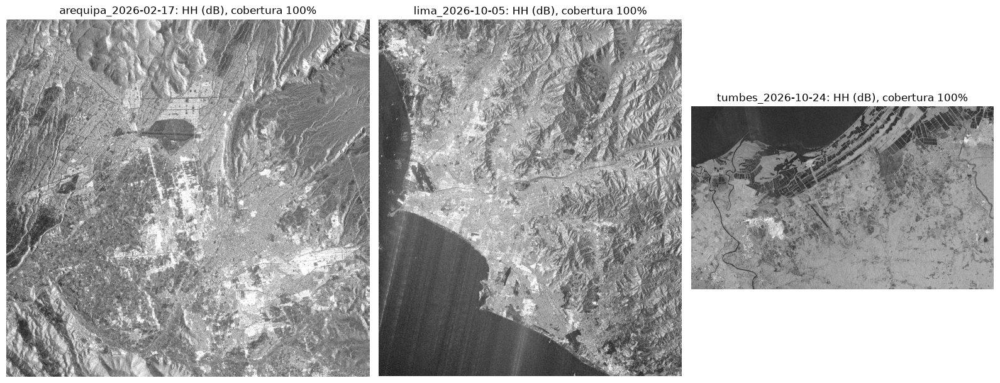

In [4]:
def leer(clave):
    ciudad, fecha = clave.split("_")[0], clave[-10:].replace("-", "")
    with rasterio.open(f"Data/procesado/nisar/{ciudad}/hh_{fecha}.tif") as f:
        hh, perfil = f.read(1), f.profile
    return hh, np.isfinite(hh), perfil


def suave(hh, valido, n=5):
    lineal = ndimage.uniform_filter(np.where(valido, 10 ** (hh / 10), 0), n)
    peso = ndimage.uniform_filter(valido.astype("float32"), n)
    return np.where(valido, 10 * np.log10(lineal / np.maximum(peso, 1e-6) + 1e-10), np.nan).astype("float32")


def etiqueta(clave):
    with rasterio.open(f"Data/procesado/etiquetas/{clave}.tif") as f:
        return f.read(1)


ejemplo = escenas[escenas.dia == "lluvia"].groupby("ciudad").clave.last()
fig, ejes = plt.subplots(1, 3, figsize=(16, 6), gridspec_kw={"width_ratios": [1.2, 1, 1]})
for ax, clave in zip(ejes, ejemplo):
    hh, valido, perfil = leer(clave)
    paso = 8 if clave.startswith("lima") else 4
    ax.imshow(suave(hh, valido, 3)[::paso, ::paso], cmap="gray", vmin=-25, vmax=5)
    ax.set_title(f"{clave}: HH (dB), cobertura {valido.mean():.0%}")
    ax.axis("off")
plt.tight_layout()

### 2.3 Pendiente y cobertura del suelo

Pendiente del DEM (las laderas en sombra de radar salen oscuras como el agua) y agua permanente de ESA WorldCover 2021, que
sirve de referencia independiente en 2.5 y para separar el mar del resto en 6 (se guarda en `worldcover.tif`).

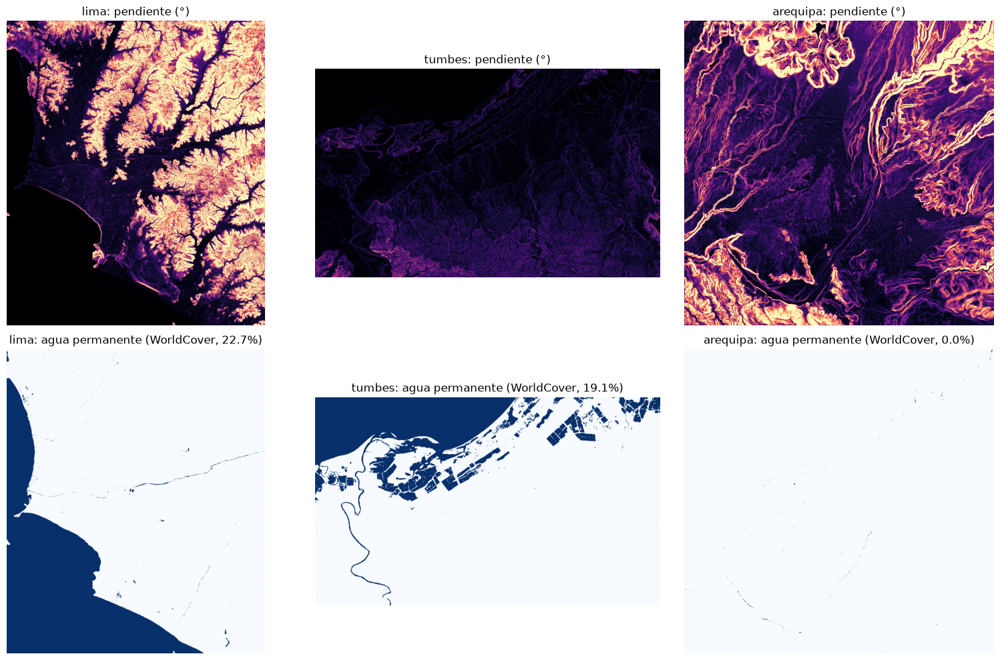

In [5]:
pendiente, worldcover = {}, {}
for ciudad in cajas:
    dem = rasterio.open(f"Data/procesado/nisar/{ciudad}/dem.tif").read(1)
    dy, dx = np.gradient(ndimage.uniform_filter(dem, 7), 5)
    pendiente[ciudad] = np.degrees(np.arctan(np.hypot(dx, dy)))
    worldcover[ciudad] = en_grilla("esa-worldcover", ciudad, Resampling.nearest)
    with rasterio.open(f"Data/procesado/nisar/{ciudad}/worldcover.tif", "w",
                       **{**grillas[ciudad], "dtype": "uint8", "nodata": 0, "predictor": 1}) as f:
        f.write(worldcover[ciudad], 1)
del dem, dx, dy
fig, ejes = plt.subplots(2, 3, figsize=(16, 10))
for j, ciudad in enumerate(cajas):
    paso = 8 if ciudad == "lima" else 4
    ejes[0, j].imshow(pendiente[ciudad][::paso, ::paso], cmap="magma", vmin=0, vmax=30)
    ejes[0, j].set_title(f"{ciudad}: pendiente (°)")
    ejes[1, j].imshow(worldcover[ciudad][::paso, ::paso] == 80, cmap="Blues")
    ejes[1, j].set_title(f"{ciudad}: agua permanente (WorldCover, {(worldcover[ciudad] == 80).mean():.1%})")
for ax in ejes.flat:
    ax.axis("off")
plt.tight_layout()

### 2.4 Etiqueta: máscara de agua del mismo día

El día de la lluvia la ciudad está nublada y no hay imagen óptica, así que la etiqueta sale del propio radar:

1. HH promediado en 5 × 5 píxeles (25 m) para bajar el moteado (*speckle*) de una imagen de una sola vista.
2. Umbral de **mínimo error de Kittler-Illingworth** sobre los píxeles planos: modela el agua y la tierra como dos campanas
   de distinto tamaño y ancho, y corta donde menos se equivoca. Sirve aunque el agua sea el 20 % o el 60 % del terreno plano
   (en la caja de Lima el mar es casi la mitad); Otsu, en cambio, supone clases parecidas y aquí parte el mar en dos. El
   umbral se limita a −12 dB: por encima ya no es agua abierta en banda L sino arena o tierra oscura.
3. Solo en terreno plano (pendiente < 5°); se borran las manchas de menos de 40 píxeles (0.1 ha).

Se hace para las escenas de lluvia y se guarda en `Data/procesado/etiquetas/`: 1 agua, 0 no agua, 255 sin dato.

In [6]:
def kittler(x):
    conteo, bordes = np.histogram(x, bins=256, range=(-40, 10))
    centro, h = (bordes[:-1] + bordes[1:]) / 2, conteo / conteo.sum()
    costo = np.full(256, np.inf)
    for t in range(1, 256):
        p1, p2 = h[:t].sum(), h[t:].sum()
        if min(p1, p2) < 0.01:
            continue
        m1, m2 = (h[:t] * centro[:t]).sum() / p1, (h[t:] * centro[t:]).sum() / p2
        v1 = (h[:t] * (centro[:t] - m1) ** 2).sum() / p1 + 0.01
        v2 = (h[t:] * (centro[t:] - m2) ** 2).sum() / p2 + 0.01
        costo[t] = p1 * np.log(v1) + p2 * np.log(v2) - 2 * (p1 * np.log(p1) + p2 * np.log(p2))
    return centro[np.argmin(costo)]


Path("Data/procesado/etiquetas").mkdir(parents=True, exist_ok=True)
lluvias = escenas[escenas.dia == "lluvia"]
umbrales = []
for e in lluvias.itertuples():
    hh, valido, perfil = leer(e.clave)
    s = suave(hh, valido)
    plano = valido & (pendiente[e.ciudad] < 5)
    x = np.random.default_rng(0).choice(s[plano], 2_000_000)
    umbral_hh = min(kittler(x), -12)
    agua = ndimage.binary_opening((s < umbral_hh) & plano, iterations=2)
    manchas, _ = ndimage.label(agua)
    agua &= np.bincount(manchas.ravel())[manchas] >= 40
    perfil.update(dtype="uint8", nodata=255, predictor=1)
    with rasterio.open(f"Data/procesado/etiquetas/{e.clave}.tif", "w", **perfil) as f:
        f.write(np.where(valido, agua, 255).astype("uint8"), 1)
    umbrales.append({"clave": e.clave, "umbral_HH_dB": umbral_hh, "agua_%": 100 * agua[valido].mean()})
del hh, s, plano, agua, manchas, pendiente
pd.DataFrame(umbrales).round(2)

,clave,umbral_HH_dB,agua_%
0,arequipa_2026-02-17,-12.00,3.29
1,lima_2026-10-24,-12.00,18.17
2,lima_2026-01-14,-12.75,46.60
3,lima_2026-08-18,-12.00,23.46
4,lima_2026-10-05,-12.00,23.95
5,tumbes_2026-10-24,-15.10,20.14


### 2.5 ¿Sirve cada escena para segmentar agua?

Se compara cada escena de lluvia con el agua permanente de WorldCover:

| Criterio | Qué mide | Umbral |
|---|---|---|
| cobertura | fracción de la caja con dato | ≥ 0.40 (el 14 ene en Lima solo hay cuadro sur) |
| AUC HH | qué tan bien separa HH el agua de la tierra (1 perfecto, 0.5 azar) | ≥ 0.90 |
| recall de la máscara | agua permanente que la máscara marca | ≥ 0.60 |
| falsa agua | tierra que la máscara marca como agua | ≤ 0.15 |

Los umbrales son más flojos que con radar de banda C: en banda L el mar con viento y la arena seca se parecen (ver
conclusiones). Una escena sin agua permanente suficiente (menos de 1000 píxeles) no se puede evaluar y no se usa para medir
la segmentación, pero sí entra en la comparación con días secos (sección 6).

In [7]:
from scipy.stats import mannwhitneyu

filas = []
for e in lluvias.itertuples():
    hh, valido, perfil = leer(e.clave)
    s, et, wc = suave(hh, valido), etiqueta(e.clave), worldcover[e.ciudad]
    agua = np.flatnonzero((et != 255) & (wc == 80))
    tierra = np.flatnonzero((et != 255) & np.isin(wc, [10, 20, 30, 40, 50, 60, 70, 100]))
    fila = {"clave": e.clave, "ciudad": e.ciudad, "rol": e.rol, "cobertura": valido.mean(), "pixeles_agua_worldcover": len(agua)}
    if len(agua) >= 1000:
        a, t = [np.random.default_rng(0).choice(x, 100_000) for x in (agua, tierra)]
        fila |= {"auc_hh": mannwhitneyu(s.flat[t], s.flat[a]).statistic / 1e10,
                 "recall_mascara": (et.flat[agua] == 1).mean(), "falsa_agua": (et.flat[tierra] == 1).mean()}
    filas.append(fila)
del hh, s, et, agua, tierra
datos = pd.DataFrame(filas)
datos["sirve"] = ((datos.cobertura >= 0.4) & (datos.auc_hh >= 0.9) & (datos.recall_mascara >= 0.6)
                  & (datos.falsa_agua <= 0.15))
datos.to_csv("Data/procesado/validacion_datos.csv", index=False)
datos.round(3)

,clave,ciudad,rol,cobertura,pixeles_agua_worldcover,auc_hh,recall_mascara,falsa_agua,sirve
0,arequipa_2026-02-17,arequipa,externa,1.000,7638,0.657,0.067,0.033,False
1,lima_2026-10-24,lima,val,1.000,23854321,0.924,0.745,0.016,True
2,lima_2026-01-14,lima,train,0.452,20429427,0.939,0.985,0.074,True
3,lima_2026-08-18,lima,train,1.000,23854321,0.942,0.939,0.028,True
4,lima_2026-10-05,lima,train,1.000,23854321,0.942,0.949,0.031,True
5,tumbes_2026-10-24,tumbes,externa,1.000,4480285,0.967,0.880,0.042,True


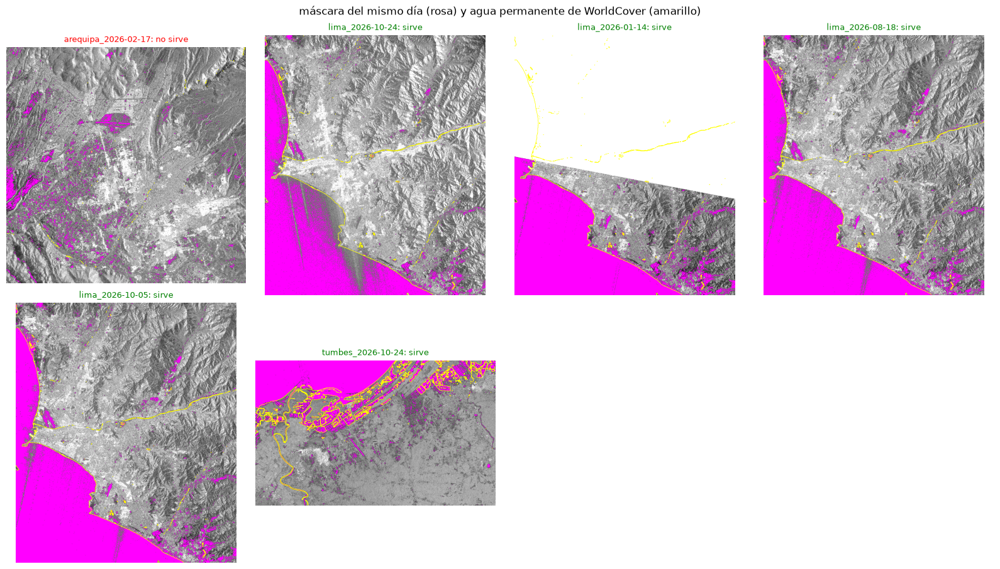

In [8]:
fig, ejes = plt.subplots(int(np.ceil(len(datos) / 4)), 4, figsize=(16, 4.6 * np.ceil(len(datos) / 4)), squeeze=False)
for ax, e in zip(ejes.flat, datos.itertuples()):
    hh, valido, perfil = leer(e.clave)
    paso = 12 if e.ciudad == "lima" else 6
    et = etiqueta(e.clave)[::paso, ::paso]
    ax.imshow(suave(hh, valido, 3)[::paso, ::paso], cmap="gray", vmin=-25, vmax=5)
    ax.imshow(np.ma.masked_where(et != 1, et), cmap="cool", vmin=0, vmax=1)
    ax.contour(worldcover[e.ciudad][::paso, ::paso] == 80, [0.5], colors="yellow", linewidths=0.5)
    ax.set_title(f"{e.clave}: {'sirve' if e.sirve else 'no sirve'}", fontsize=9, color="green" if e.sirve else "red")
for ax in ejes.flat:
    ax.axis("off")
plt.suptitle("máscara del mismo día (rosa) y agua permanente de WorldCover (amarillo)")
plt.tight_layout()

### 2.6 Parches

Las escenas de train y validación que sirven se cortan en parches de 256 × 256 píxeles (1.28 km) con al menos la mitad de
píxeles con dato. `X` = HH promediado 5 × 5 en dB, igual que en la etiqueta: baja el moteado, cuyo grano además cambia de
una imagen de 20 MHz (Lima, Arequipa) a una de 40 MHz (Tumbes); `Y` = etiqueta, `M` = píxeles evaluables.

In [9]:
usar = datos[datos.sirve & datos.rol.isin(["train", "val"])]
X, Y, M, info = [], [], [], []
for e in usar.itertuples():
    hh, valido, perfil = leer(e.clave)
    s, et = suave(hh, valido), etiqueta(e.clave)
    for i in range(0, et.shape[0] - 255, 256):
        for j in range(0, et.shape[1] - 255, 256):
            p = et[i:i + 256, j:j + 256]
            if (p != 255).mean() < 0.5:
                continue
            X.append(s[None, i:i + 256, j:j + 256].astype("float16"))
            Y.append(p == 1)
            M.append(p != 255)
            info.append({"clave": e.clave, "rol": e.rol, "agua": (p == 1).mean(), "con_dato": (p != 255).mean()})
del hh, s, et
X, Y, M, info = np.array(X), np.array(Y), np.array(M), pd.DataFrame(info)
tr, va = (info.rol == "train").to_numpy(), (info.rol == "val").to_numpy()
info.groupby(["rol", "clave"]).agg(parches=("agua", "size"), agua_media=("agua", "mean")).round(3)

parches  agua_media
rol   clave                               
train lima_2026-01-14      692       0.464
      lima_2026-08-18     1548       0.233
      lima_2026-10-05     1548       0.238
val   lima_2026-10-24     1548       0.179

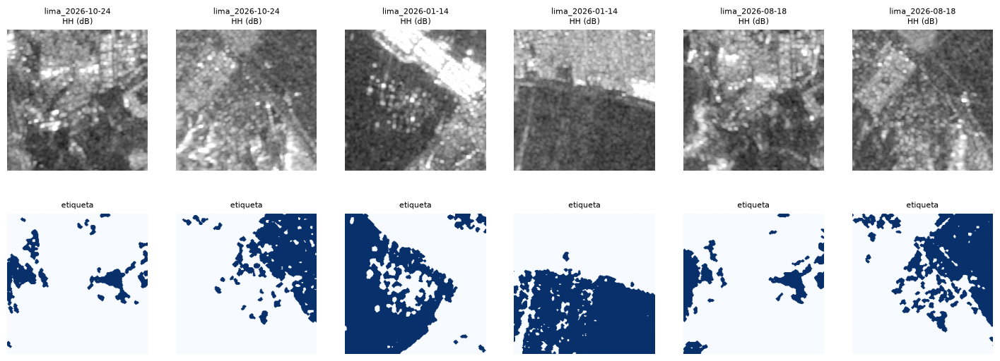

In [10]:
ejemplos = info[info.agua.between(0.05, 0.5) & (info.con_dato == 1)].groupby("clave").head(2).index[:6]
fig, ejes = plt.subplots(2, len(ejemplos), figsize=(3 * len(ejemplos), 6.2), squeeze=False)
for c, k in enumerate(ejemplos):
    ejes[0, c].imshow(X[k, 0].astype("float32"), cmap="gray", vmin=-25, vmax=5)
    ejes[0, c].set_title(f"{info.clave[k]}\nHH (dB)", fontsize=8)
    ejes[1, c].imshow(np.where(M[k], Y[k], np.nan), cmap="Blues", vmin=0, vmax=1)
    ejes[1, c].set_title("etiqueta", fontsize=8)
for ax in ejes.flat:
    ax.axis("off")

## 3. Normalización

HH se recorta a [−35, 10] dB y se estandariza con la media y la desviación de los parches de **train** (sin mirar validación
ni la aplicación externa). Los píxeles sin dato quedan en 0, que equivale a la media.

In [11]:
entrenamiento = np.clip(X[tr].astype("float32"), -35, 10)
media = np.nanmean(entrenamiento, axis=(0, 2, 3))
desv = np.nanstd(entrenamiento, axis=(0, 2, 3))
del entrenamiento


def normalizar(x):
    return np.nan_to_num((np.clip(x.astype("float32"), -35, 10) - media[:, None, None]) / desv[:, None, None])


muestra = normalizar(X[tr][:200])
pd.DataFrame({"media dB": media, "desviación dB": desv, "media normalizada": muestra.mean(axis=(0, 2, 3)),
              "desviación normalizada": muestra.std(axis=(0, 2, 3))}, index=["HH"]).round(3)

,media dB,desviación dB,media normalizada,desviación normalizada
HH,-9.098,6.692,-0.074,1.032


## 4. Modelo: U-Net

La **U-Net** resume la imagen en mapas cada vez más pequeños (codificador) y luego recupera la resolución (decodificador) con
conexiones de salto, para dar una probabilidad de agua por píxel. Se prueban tres codificadores preentrenados en ImageNet:
ResNet34, EfficientNet-B0 y MobileNetV2, con un solo canal de entrada (HH promediado).

* Pérdida: entropía cruzada binaria + Dice, solo en píxeles evaluables.
* AdamW (lr 1e-4), lotes de 16, giros de 90° al azar.
* A cada parche se le suma al azar entre −3 y +3 dB: la calibración y el viento sobre el mar cambian el nivel de una imagen a
  otra, y la red debe fijarse en el contraste y la forma, no en el nivel absoluto.
* Hasta 30 épocas; se para si el IoU de validación no mejora en 5. Se guarda la época con mejor IoU.
* El umbral de decisión se elige en validación.

In [12]:
import torch, segmentation_models_pytorch as smp

gpu = "cuda" if torch.cuda.is_available() else "cpu"
Xtr = torch.tensor(normalizar(X[tr]), dtype=torch.float16, device=gpu)
Ytr = torch.tensor(Y[tr][:, None], device=gpu)
Mtr = torch.tensor(M[tr][:, None], device=gpu)
Xva = torch.tensor(normalizar(X[va]), dtype=torch.float16, device=gpu)
Yva = torch.tensor(Y[va][:, None], device=gpu)
Mva = torch.tensor(M[va][:, None], device=gpu)


def perdida(logits, y, m):
    y, m = y.float(), m.float()
    bce = (torch.nn.functional.binary_cross_entropy_with_logits(logits, y, reduction="none") * m).sum() / m.sum()
    p = torch.sigmoid(logits) * m
    return bce + 1 - (2 * (p * y).sum() + 1) / (p.sum() + (y * m).sum() + 1)


def predecir(modelo, x):
    modelo.eval()
    with torch.no_grad(), torch.autocast(gpu, dtype=torch.bfloat16):
        return torch.cat([torch.sigmoid(modelo(x[i:i + 32].float())).float() for i in range(0, len(x), 32)])


def metricas(p, y, m, umbral):
    a = p >= umbral
    tp, fp, fn = (a & y & m).sum().item(), (a & ~y & m).sum().item(), (~a & y & m).sum().item()
    return {"IoU": tp / max(tp + fp + fn, 1), "F1": 2 * tp / max(2 * tp + fp + fn, 1),
            "Precision": tp / max(tp + fp, 1), "Recall": tp / max(tp + fn, 1)}


print(gpu, "· train", tuple(Xtr.shape), "· val", tuple(Xva.shape))

cuda · train (3788, 1, 256, 256) · val (1548, 1, 256, 256)


In [13]:
Path("Data/procesado/dl").mkdir(parents=True, exist_ok=True)
historial, resultados = [], []
for encoder in ["resnet34", "efficientnet-b0", "mobilenet_v2"]:
    torch.manual_seed(0)
    np.random.seed(0)
    modelo = smp.Unet(encoder, encoder_weights="imagenet", in_channels=1, classes=1).to(gpu)
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=1e-4)
    mejor_iou, sin_mejora = 0, 0
    for epoca in range(1, 31):
        modelo.train()
        perdidas = []
        for lote in torch.randperm(len(Xtr), device=gpu).split(16):
            k = np.random.randint(4)
            x, y, m = [t[lote].rot90(k, [2, 3]) for t in (Xtr, Ytr, Mtr)]
            x = x.float() + (torch.rand(len(x), 1, 1, 1, device=gpu) * 6 - 3) / float(desv[0])
            with torch.autocast(gpu, dtype=torch.bfloat16):
                logits = modelo(x)
            loss = perdida(logits.float(), y, m)
            optimizador.zero_grad()
            loss.backward()
            optimizador.step()
            perdidas.append(loss.item())
        p = predecir(modelo, Xva)
        iou = metricas(p, Yva, Mva, 0.5)["IoU"]
        historial.append({"encoder": encoder, "epoca": epoca, "perdida_train": np.mean(perdidas),
                          "perdida_val": perdida(torch.logit(p.clamp(1e-6, 1 - 1e-6)), Yva, Mva).item(), "iou_val": iou})
        print(f"{encoder} · época {epoca} · pérdida train {np.mean(perdidas):.3f} · IoU val {iou:.3f}")
        if iou > mejor_iou:
            mejor_iou, mejor_epoca, sin_mejora = iou, epoca, 0
            pesos = {k: v.clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1
            if sin_mejora == 5:
                break
    modelo.load_state_dict(pesos)
    p = predecir(modelo, Xva)
    umbral = max(np.arange(0.1, 0.95, 0.05).round(2), key=lambda u: metricas(p, Yva, Mva, u)["IoU"])
    torch.save({"pesos": pesos, "encoder": encoder, "media": media.tolist(), "desv": desv.tolist(), "umbral": float(umbral)},
               f"Data/procesado/dl/unet_{encoder}.pt")
    resultados.append({"encoder": encoder, "mejor_epoca": mejor_epoca, "umbral": umbral, **metricas(p, Yva, Mva, umbral)})

resnet34 · época 1 · pérdida train 0.727 · IoU val 0.712


resnet34 · época 2 · pérdida train 0.382 · IoU val 0.637


resnet34 · época 3 · pérdida train 0.278 · IoU val 0.744


resnet34 · época 4 · pérdida train 0.221 · IoU val 0.717


resnet34 · época 5 · pérdida train 0.193 · IoU val 0.001


resnet34 · época 6 · pérdida train 0.185 · IoU val 0.739


... (11 outputs left out)

mobilenet_v2 · época 4 · pérdida train 0.179 · IoU val 0.739


mobilenet_v2 · época 5 · pérdida train 0.172 · IoU val 0.086


mobilenet_v2 · época 6 · pérdida train 0.160 · IoU val 0.253


mobilenet_v2 · época 7 · pérdida train 0.155 · IoU val 0.571


## 5. Resultados en validación

**IoU** = intersección / unión del agua predicha y la etiqueta; **F1** = media armónica de precisión y recall. Todo se mide
sobre los píxeles evaluables de la escena de validación.

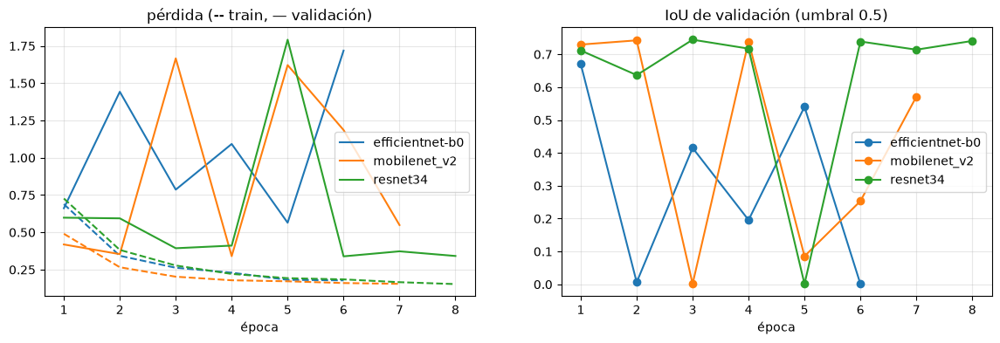

In [14]:
historial = pd.DataFrame(historial)
historial.to_csv("Data/procesado/dl/historial.csv", index=False)
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
for encoder, h in historial.groupby("encoder"):
    linea, = ejes[0].plot(h.epoca, h.perdida_train, "--")
    ejes[0].plot(h.epoca, h.perdida_val, color=linea.get_color(), label=encoder)
    ejes[1].plot(h.epoca, h.iou_val, "o-", label=encoder)
ejes[0].set_title("pérdida (-- train, — validación)")
ejes[1].set_title("IoU de validación (umbral 0.5)")
for ax in ejes:
    ax.set_xlabel("época")
    ax.grid(alpha=0.3)
    ax.legend()

In [15]:
resultados = pd.DataFrame(resultados).sort_values("IoU", ascending=False)
resultados.to_csv("Data/procesado/dl/resultados_validacion.csv", index=False)
mejor = resultados.encoder.iloc[0]
print("mejor encoder:", mejor)
resultados.round(3)

mejor encoder: resnet34


,encoder,mejor_epoca,umbral,IoU,F1,Precision,Recall
0,resnet34,3,0.40,0.752,0.859,0.822,0.898
2,mobilenet_v2,2,0.75,0.749,0.856,0.827,0.888
1,efficientnet-b0,1,0.30,0.705,0.827,0.777,0.883


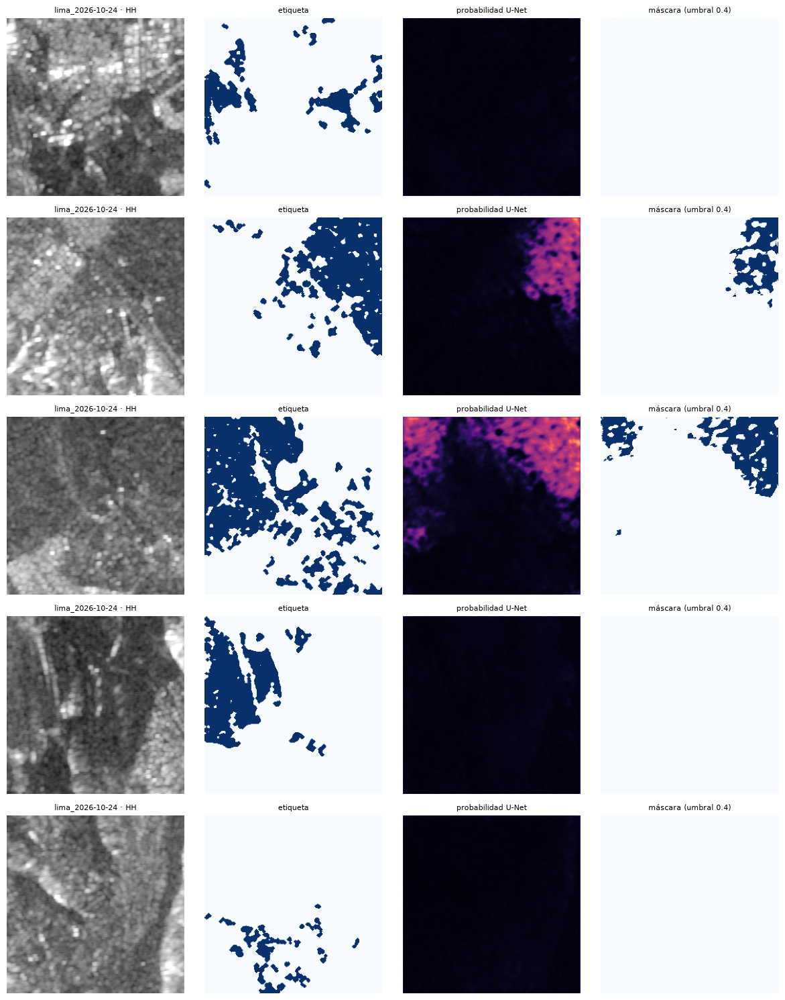

In [16]:
guardado = torch.load(f"Data/procesado/dl/unet_{mejor}.pt")
modelo = smp.Unet(mejor, encoder_weights=None, in_channels=1, classes=1).to(gpu)
modelo.load_state_dict(guardado["pesos"])
umbral = guardado["umbral"]
p = predecir(modelo, Xva)
info_va = info[va].reset_index(drop=True)
ejemplos = info_va[info_va.agua.between(0.05, 0.5) & (info_va.con_dato == 1)].head(5).index
fig, ejes = plt.subplots(len(ejemplos), 4, figsize=(12, 3 * len(ejemplos)), squeeze=False)
for fila, k in zip(ejes, ejemplos):
    fila[0].imshow(X[va][k, 0].astype("float32"), cmap="gray", vmin=-25, vmax=5)
    fila[0].set_title(f"{info_va.clave[k]} · HH", fontsize=8)
    fila[1].imshow(Yva[k, 0].cpu(), cmap="Blues")
    fila[1].set_title("etiqueta", fontsize=8)
    fila[2].imshow(p[k, 0].cpu(), cmap="magma", vmin=0, vmax=1)
    fila[2].set_title("probabilidad U-Net", fontsize=8)
    fila[3].imshow((p[k, 0] >= umbral).cpu(), cmap="Blues")
    fila[3].set_title(f"máscara (umbral {umbral})", fontsize=8)
for ax in ejes.flat:
    ax.axis("off")
plt.tight_layout()

## 6. Aplicación externa: Tumbes y Arequipa

Cada escena completa (lluvias y días secos de las tres ciudades) se predice con una ventana deslizante (256 px, paso 128,
promedio en los solapes) y su probabilidad se guarda como GeoTIFF en `Data/procesado/dl/predicciones/` (×100, 255 = sin
dato). Las lluvias externas que sirven se comparan con su máscara del mismo día.

Después se separa el acierto por zona, en validación y en las externas: el **agua permanente** de WorldCover (mar, ríos,
langostineras) y la **tierra a más de 200 m** de ella, que es donde estaría el agua empozada en la ciudad.

In [17]:
def mapa(modelo, hh):
    modelo.eval()
    x = normalizar(hh[None])
    alto, ancho = hh.shape
    suma, veces = np.zeros((alto, ancho), "float32"), np.zeros((alto, ancho), "float32")
    filas = list(range(0, alto - 256, 128)) + [alto - 256]
    columnas = list(range(0, ancho - 256, 128)) + [ancho - 256]
    with torch.no_grad(), torch.autocast(gpu, dtype=torch.bfloat16):
        for i in filas:
            lote = torch.tensor(np.stack([x[:, i:i + 256, j:j + 256] for j in columnas]), dtype=torch.float32, device=gpu)
            prob = torch.sigmoid(modelo(lote)).float().cpu().numpy()[:, 0]
            for j, pj in zip(columnas, prob):
                suma[i:i + 256, j:j + 256] += pj
                veces[i:i + 256, j:j + 256] += 1
    return suma / veces


del Xtr, Ytr, Mtr, Xva, Yva, Mva, X, Y, M
torch.cuda.empty_cache()
Path("Data/procesado/dl/predicciones").mkdir(exist_ok=True)
sirve = set(datos.clave[datos.sirve])
externa = []
for e in escenas.itertuples():
    hh, valido, perfil = leer(e.clave)
    p = np.where(valido, mapa(modelo, suave(hh, valido)), np.nan)
    if e.rol == "externa" and e.clave in sirve:
        et = etiqueta(e.clave)
        externa.append({"clave": e.clave, **metricas(p, et == 1, et != 255, umbral)})
    perfil.update(dtype="uint8", nodata=255, predictor=1)
    with rasterio.open(f"Data/procesado/dl/predicciones/{e.clave}.tif", "w", **perfil) as f:
        f.write(np.where(valido, np.round(np.nan_to_num(p) * 100), 255).astype("uint8"), 1)
del hh, p
externa = pd.DataFrame(externa, columns=["clave", "IoU", "F1", "Precision", "Recall"])
externa.to_csv("Data/procesado/dl/resultados_externa.csv", index=False)
externa.round(3)

,clave,IoU,F1,Precision,Recall
0,tumbes_2026-10-24,0.813,0.897,0.84,0.962


In [18]:
lejos = {k: ndimage.maximum_filter((w == 80).astype("uint8"), 81) == 0 for k, w in worldcover.items()}
filas = []
for c in [*datos.clave[datos.sirve & (datos.rol == "val")], *externa.clave]:
    et, wc, lj = etiqueta(c), worldcover[c.split("_")[0]], lejos[c.split("_")[0]]
    with rasterio.open(f"Data/procesado/dl/predicciones/{c}.tif") as f:
        p = f.read(1).astype("float32") / 100
    for zona, m in [("todo", et != 255), ("agua permanente", (et != 255) & (wc == 80)), ("tierra a más de 200 m", (et != 255) & lj)]:
        filas.append({"clave": c, "zona": zona, "km2": m.sum() * 25 / 1e6, "agua_etiqueta_%": 100 * (et[m] == 1).mean(),
                      "agua_unet_%": 100 * (p[m] >= umbral).mean(), **metricas(p[m], et[m] == 1, et[m] != 255, umbral)})
del et, wc, lj, p, m
por_zona = pd.DataFrame(filas)
por_zona.to_csv("Data/procesado/dl/resultados_por_zona.csv", index=False)
por_zona.round(3)

,clave,zona,km2,agua_etiqueta_%,agua_unet_%,IoU,F1,Precision,Recall
0,lima_2026-10-24,todo,2628.544,18.172,19.863,0.758,0.863,0.826,0.903
1,lima_2026-10-24,agua permanente,596.358,74.507,87.240,0.806,0.893,0.827,0.969
2,lima_2026-10-24,tierra a más de 200 m,1921.628,1.432,0.092,0.022,0.043,0.359,0.023
3,tumbes_2026-10-24,todo,585.678,20.145,23.140,0.811,0.896,0.838,0.962
4,tumbes_2026-10-24,agua permanente,112.007,88.016,91.890,0.930,0.964,0.943,0.985
5,tumbes_2026-10-24,tierra a más de 200 m,394.304,1.939,3.852,0.319,0.484,0.364,0.722


### 6.1 ¿Hay agua de la lluvia? Comparación con días secos

El mar, los ríos, las lagunas de oxidación, las langostineras de Tumbes y la arena oscura salen como agua cualquier día. Cada
lluvia se compara solo con los días secos de su **misma ciudad y pista**. Antes, cada imagen se lleva a la calibración media
de los días secos de su pista (se le resta la diferencia de la mediana de la zona común).

**Agua de lluvia** = agua según la U-Net ese día, que en los días secos casi nunca es agua (≤ 20 %) y donde HH (promedio
5 × 5) bajó más de 3 dB respecto de la mediana seca. Para saber cuánto marca este criterio sin lluvia, se aplica también a
cada día seco contra los otros.

En cada lluvia se mira además el agua que la **etiqueta** marca en tierra (a más de 200 m del agua permanente) y qué parte de
ella ya está oscura (bajo −12 dB) en la mediana de los días secos: si casi toda lo está, es arena, suelo o pozas de siempre y
no agua de la lluvia.

Las imágenes de Lima tienen unos 100 millones de píxeles, así que se procesa una pista a la vez. En la misma pasada se mide
el cambio de HH en los lugares con noticias de la sección 6.2.

In [19]:
import warnings
warnings.filterwarnings("ignore", message="All-NaN slice")


def agua_unet(c):
    with rasterio.open(f"Data/procesado/dl/predicciones/{c}.tif") as f:
        p = f.read(1)
    return (p >= umbral * 100) & (p != 255)


def mediana(pilas):
    return np.concatenate([np.nanmedian(np.stack([p[i:i + 500] for p in pilas]), 0)
                           for i in range(0, len(pilas[0]), 500)]).astype("float32")


def en_ventanas(dif, urbano, lado):
    ok = urbano & ~np.isnan(dif)
    suma = ndimage.uniform_filter(np.where(ok, dif, 0), lado)
    peso = ndimage.uniform_filter(ok.astype("float32"), lado)
    return np.where(peso > 0.6, suma / np.maximum(peso, 1e-6), np.nan)


noticias = pd.DataFrame([
    ("lima", "baipás Nueva Esperanza", -12.1804, -76.9435, 60, "lima_2026-08-18", "bus varado en el baipás, 17 ago (Andina)"),
    ("lima", "VES Sector 1 Grupo 1", -12.1874, -76.9471, 200, "lima_2026-08-18", "aguas servidas en 11 manzanas, 16-18 ago (Infobae)"),
    ("lima", "VMT José Gálvez", -12.2244, -76.9029, 300, "lima_2026-08-18", "viviendas inundadas, 17 ago (Caretas)"),
    ("lima", "baipás Nueva Esperanza", -12.1804, -76.9435, 60, "lima_2026-10-05", "inundado la madrugada del 2 oct (La República)"),
    ("lima", "baipás Nueva Esperanza", -12.1804, -76.9435, 60, "lima_2026-11-05", "inundado y cerrado el 5 nov (El Búho)"),
    ("lima", "VES Sector 1 Grupo 1", -12.1874, -76.9471, 200, "lima_2026-11-05", "desagüe colapsado, 4-5 nov (Caretas)"),
    ("lima", "Hospital de Emergencias VES", -12.2321, -76.9348, 100, "lima_2026-11-05", "aniego en el exterior, 5 nov (Andina)"),
    ("tumbes", "Puerto Pizarro", -3.5028, -80.3915, 400, "tumbes_2026-10-24", "“todito Pizarro está inundado”, 23 oct (América TV)"),
    ("tumbes", "Tumbes: barrio San José", -3.5696, -80.4613, 300, "tumbes_2026-10-24", "aniegos en el barrio San José, 23 oct (América TV)"),
    ("tumbes", "Zarumilla", -3.5006, -80.2750, 400, "tumbes_2026-10-24", "agua acumulada en las calles, 23 oct (América TV)"),
    ("arequipa", "baipás Av. Venezuela - Mariscal Castilla", -16.4021, -71.5173, 60, "arequipa_2026-02-17",
     "zanjón del baipás inundado, 2 vehículos varados, 16 feb (La República, Infobae)"),
    ("arequipa", "Av. Goyeneche (Cercado)", -16.4007, -71.5272, 150, "arequipa_2026-02-17", "corría el agua de lluvia, 16 feb (Infobae)"),
    ("arequipa", "Ciudad de Dios (Yura)", -16.3084, -71.6149, 400, "arequipa_2026-02-17", "45 viviendas inundadas, 16 feb (Infobae)"),
], columns=["ciudad", "lugar", "lat", "lon", "radio_m", "escena", "noticia"])
noticias = noticias[noticias.escena.isin(escenas.clave)].reset_index(drop=True)
noticias["lado"] = 2 * (noticias.radio_m // 5) + 1
noticias["fila"], noticias["col"] = zip(*[rowcol(grillas[n.ciudad]["transform"], *Transformer.from_crs(
    "EPSG:4326", grillas[n.ciudad]["crs"], always_xy=True).transform(n.lon, n.lat)) for n in noticias.itertuples()])
noticias[["ciudad", "lugar", "radio_m", "escena", "noticia"]]

,ciudad,lugar,radio_m,escena,noticia
0,lima,baipás Nueva Esperanza,60,lima_2026-08-18,"bus varado en el baipás, 17 ago (Andina)"
1,lima,VES Sector 1 Grupo 1,200,lima_2026-08-18,"aguas servidas en 11 manzanas, 16-18 ago (Info..."
2,lima,VMT José Gálvez,300,lima_2026-08-18,"viviendas inundadas, 17 ago (Caretas)"
3,lima,baipás Nueva Esperanza,60,lima_2026-10-05,inundado la madrugada del 2 oct (La República)
4,tumbes,Puerto Pizarro,400,tumbes_2026-10-24,"“todito Pizarro está inundado”, 23 oct (Améric..."
5,tumbes,Tumbes: barrio San José,300,tumbes_2026-10-24,"aniegos en el barrio San José, 23 oct (América..."
6,tumbes,Zarumilla,400,tumbes_2026-10-24,"agua acumulada en las calles, 23 oct (América TV)"
7,arequipa,baipás Av. Venezuela - Mariscal Castilla,60,arequipa_2026-02-17,"zanjón del baipás inundado, 2 vehículos varado..."
8,arequipa,Av. Goyeneche (Cercado),150,arequipa_2026-02-17,"corría el agua de lluvia, 16 feb (Infobae)"
9,arequipa,Ciudad de Dios (Yura),400,arequipa_2026-02-17,"45 viviendas inundadas, 16 feb (Infobae)"


In [20]:
rng = np.random.default_rng(0)
filas, vista_lluvia, sitio, en_secos, vistas = [], {}, {}, {}, {}
for (ciudad, pista), g in escenas.groupby(["ciudad", "pista"]):
    secos_g = list(g.clave[g.dia == "seco"])
    hs = {c: suave(*leer(c)[:2]).astype("float16") for c in g.clave}
    total = sum(agua_unet(r).astype("uint8") for r in secos_g)
    muestra = rng.choice(hs[secos_g[0]].size, 2_000_000)
    comun = np.logical_and.reduce([np.isfinite(hs[c].flat[muestra]) for c in g.clave])
    nivel = {c: np.median(hs[c].flat[muestra][comun].astype("float32")) for c in g.clave}
    for c in g.clave:
        hs[c] -= np.float16(nivel[c] - np.median([nivel[r] for r in secos_g]))
    for c in g.clave:
        dia = "seco" if c in secos_g else "lluvia"
        refs = [r for r in secos_g if r != c]
        med = mediana([hs[r] for r in refs])
        dif = hs[c] - med
        agua = agua_unet(c)
        veces = total - agua if dia == "seco" else total
        m = ndimage.binary_opening(agua & (veces <= 0.2 * len(refs)) & (dif < -3))
        tierra = (etiqueta(c) == 1) & lejos[ciudad] if dia == "lluvia" else None
        filas.append({"ciudad": ciudad, "pista": pista, "escena": c, "dia": dia,
                      "agua_unet_km2": agua.sum() * 25 / 1e6, "agua_de_lluvia_km2": m.sum() * 25 / 1e6,
                      "etiqueta_en_tierra_km2": tierra.sum() * 25 / 1e6 if dia == "lluvia" else np.nan,
                      "oscura_en_secos_%": 100 * (med[tierra] < -12).mean() if dia == "lluvia" else np.nan})
        if dia == "lluvia":
            paso = 10 if ciudad == "lima" else 5
            vista_lluvia[c] = (hs[c][::paso, ::paso].astype("float32"),
                               ndimage.binary_dilation(m, iterations=paso)[::paso, ::paso], m.sum() * 25 / 1e6)
        for n in noticias[noticias.escena.isin(g.clave)].itertuples():
            if c != n.escena and dia == "lluvia":
                continue
            v = en_ventanas(dif, med > -10, n.lado)
            if c != n.escena:
                en_secos.setdefault(n.Index, []).append(float(v[n.fila, n.col]))
                continue
            zona = np.s_[n.fila - n.lado // 2:n.fila + n.lado // 2 + 1, n.col - n.lado // 2:n.col + n.lado // 2 + 1]
            resto = v[::n.lado // 2 + 1, ::n.lado // 2 + 1]
            resto = resto[~np.isnan(resto)]
            sitio[n.Index] = {"unet_agua_m2": int(agua[zona].sum()) * 25, "agua_de_lluvia_m2": int(m[zona].sum()) * 25,
                              "cambio_HH_dB": round(float(v[n.fila, n.col]), 2),
                              "zonas_que_cambian_menos_%": round(float((resto < v[n.fila, n.col]).mean() * 100), 1)}
            cerca = np.s_[n.fila - 180:n.fila + 180, n.col - 180:n.col + 180]
            vistas[n.Index] = (hs[c][cerca].astype("float32"), med[cerca], ndimage.uniform_filter(np.nan_to_num(dif[cerca]), 9))
    del hs, total, agua, med, dif, m, veces, tierra
comparacion = pd.DataFrame(filas)
comparacion.to_csv("Data/procesado/dl/agua_de_lluvia.csv", index=False)
comparacion.groupby(["ciudad", "pista", "dia"]).agua_de_lluvia_km2.agg(["min", "max"]).round(3)

min     max
ciudad   pista dia                  
arequipa 046_A lluvia  0.012   0.012
               seco    0.035   0.118
lima     003_A lluvia  0.257   0.257
               seco    0.078   4.938
         083_D lluvia  0.309   0.745
               seco    0.122   0.451
tumbes   003_A lluvia  0.993   0.993
               seco    2.682  13.405

In [21]:
comparacion[comparacion.dia == "lluvia"].round(3)

,ciudad,pista,escena,dia,agua_unet_km2,agua_de_lluvia_km2,etiqueta_en_tierra_km2,oscura_en_secos_%
0,arequipa,046_A,arequipa_2026-02-17,lluvia,0.659,0.012,14.269,86.561
8,lima,003_A,lima_2026-10-24,lluvia,522.102,0.257,27.518,80.239
11,lima,083_D,lima_2026-01-14,lluvia,497.400,0.470,41.915,85.259
15,lima,083_D,lima_2026-08-18,lluvia,568.702,0.745,45.813,95.883
17,lima,083_D,lima_2026-10-05,lluvia,569.684,0.309,51.628,93.509
21,tumbes,003_A,tumbes_2026-10-24,lluvia,135.523,0.993,7.647,97.679


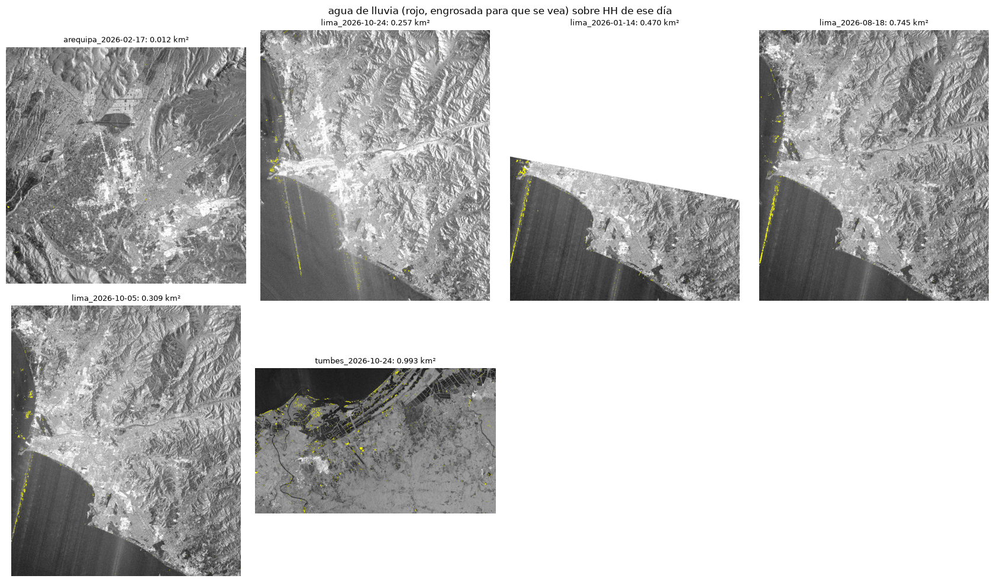

In [22]:
fig, ejes = plt.subplots(int(np.ceil(len(vista_lluvia) / 4)), 4, figsize=(17, 5 * np.ceil(len(vista_lluvia) / 4)), squeeze=False)
for ax, (c, (fondo, mancha, km2)) in zip(ejes.flat, vista_lluvia.items()):
    ax.imshow(fondo, cmap="gray", vmin=-25, vmax=5)
    ax.imshow(np.where(mancha, 1.0, np.nan), cmap="autumn", vmin=0, vmax=1)
    ax.set_title(f"{c}: {km2:.3f} km²", fontsize=9)
for ax in ejes.flat:
    ax.axis("off")
plt.suptitle("agua de lluvia (rojo, engrosada para que se vea) sobre HH de ese día")
plt.tight_layout()

### 6.2 ¿Queda agua empozada en los lugares de las noticias?

Lugares que la prensa reportó inundados y la pasada de NISAR de ese día o del siguiente. En un cuadrado del tamaño del lugar
se mide:

* cuánta agua marca la U-Net y cuánta queda como agua de lluvia (6.1);
* cuánto cambió HH respecto de la mediana de los días secos de la misma pista. El agua junto a paredes *sube* HH (doble
  rebote) y el agua abierta y lisa lo *baja*;
* el rango de ese cambio en los días secos (cada uno contra los otros);
* qué porcentaje de las zonas urbanas de la misma ciudad y del mismo tamaño cambió menos ese día. Si el lugar inundado fuera
  detectable, estaría cerca del 0 % (bajó mucho) o del 100 % (subió mucho).

| Pasada | Horas después de la lluvia |
|---|---|
| Arequipa 17 feb, 05:32 | ~13 h (lluvia desde las 16:00 del 16 feb) |
| Tumbes 24 oct, 06:01 | ~24 h (8 h de lluvia la madrugada del 23 oct) |
| Lima 18 ago, 18:25 | ~1 día (lluvia del 16-17 ago) |
| Lima 5 oct, 18:25 | 3 días (aniego del 2 oct) |
| Lima 5 nov, 05:58 | horas (aniegos de la noche del 4 al 5 nov), si ya está publicada |

In [23]:
resultado = pd.DataFrame([{"lugar": n.lugar, "escena": n.escena, "noticia": n.noticia, **sitio[n.Index],
                           "dias_secos_dB": f"{np.nanmin(en_secos[n.Index]):+.2f} a {np.nanmax(en_secos[n.Index]):+.2f}"}
                          for n in noticias.itertuples()])
resultado.to_csv("Data/procesado/dl/validacion_noticias.csv", index=False)
resultado

,lugar,escena,noticia,unet_agua_m2,agua_de_lluvia_m2,cambio_HH_dB,zonas_que_cambian_menos_%,dias_secos_dB
0,baipás Nueva Esperanza,lima_2026-08-18,"bus varado en el baipás, 17 ago (Andina)",0,0,-0.43,19.4,-0.81 a +1.26
1,VES Sector 1 Grupo 1,lima_2026-08-18,"aguas servidas en 11 manzanas, 16-18 ago (Info...",0,0,-0.12,61.5,-0.50 a +0.77
2,VMT José Gálvez,lima_2026-08-18,"viviendas inundadas, 17 ago (Caretas)",0,0,0.14,83.4,-0.25 a +0.43
3,baipás Nueva Esperanza,lima_2026-10-05,inundado la madrugada del 2 oct (La República),0,0,-0.01,36.5,-0.81 a +1.26
4,Puerto Pizarro,tumbes_2026-10-24,"“todito Pizarro está inundado”, 23 oct (Améric...",86175,2375,-1.67,17.8,-0.36 a +0.15
5,Tumbes: barrio San José,tumbes_2026-10-24,"aniegos en el barrio San José, 23 oct (América...",47100,0,-1.97,13.0,-0.25 a +0.03
6,Zarumilla,tumbes_2026-10-24,"agua acumulada en las calles, 23 oct (América TV)",75,0,-1.37,25.4,-0.36 a +0.18
7,baipás Av. Venezuela - Mariscal Castilla,arequipa_2026-02-17,"zanjón del baipás inundado, 2 vehículos varado...",0,0,-1.35,21.7,-0.03 a -0.01
8,Av. Goyeneche (Cercado),arequipa_2026-02-17,"corría el agua de lluvia, 16 feb (Infobae)",0,0,-1.59,7.7,-0.21 a +0.18
9,Ciudad de Dios (Yura),arequipa_2026-02-17,"45 viviendas inundadas, 16 feb (Infobae)",0,0,-0.96,35.1,-0.19 a +0.06


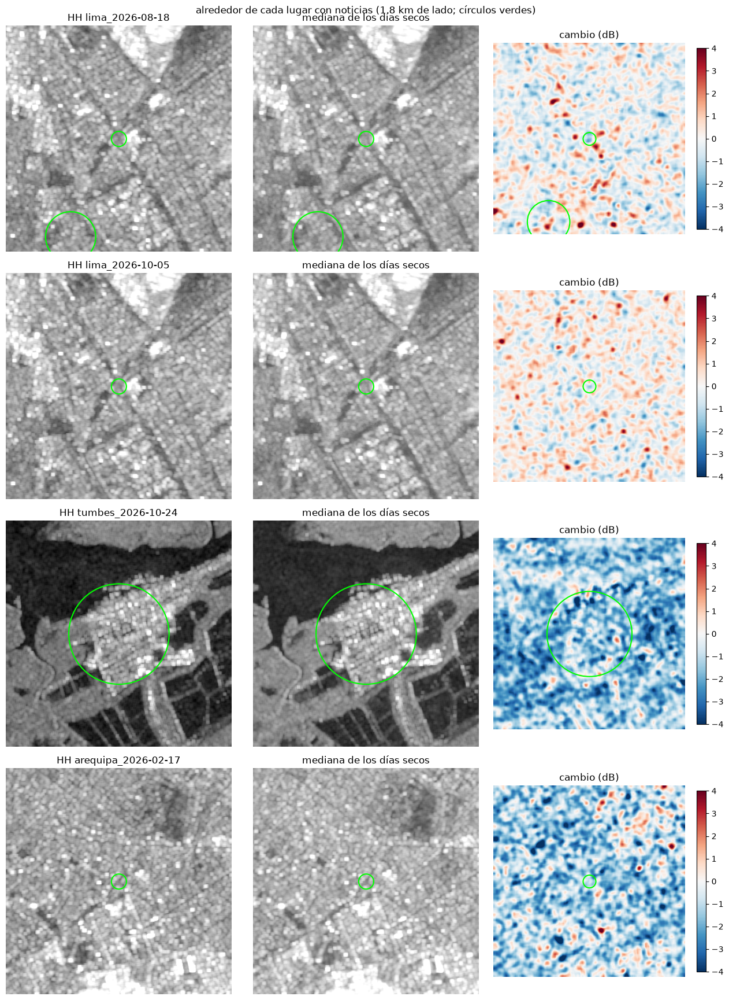

In [24]:
casos = noticias.drop_duplicates("escena")
fig, ejes = plt.subplots(len(casos), 3, figsize=(13, 4.4 * len(casos)), squeeze=False)
for fila, n in zip(ejes, casos.itertuples()):
    hs_v, med_v, dif_v = vistas[n.Index]
    fila[0].imshow(hs_v, cmap="gray", vmin=-25, vmax=5)
    fila[0].set_title(f"HH {n.escena}")
    fila[1].imshow(med_v, cmap="gray", vmin=-25, vmax=5)
    fila[1].set_title("mediana de los días secos")
    im = fila[2].imshow(dif_v, cmap="RdBu_r", vmin=-4, vmax=4)
    fila[2].set_title("cambio (dB)")
    plt.colorbar(im, ax=fila[2], shrink=0.8)
    for ax in fila:
        for m in noticias[noticias.escena == n.escena].itertuples():
            ax.add_patch(plt.Circle((m.col - n.col + 180, m.fila - n.fila + 180), m.radio_m / 5, fill=False, color="lime", lw=1.5))
        ax.axis("off")
plt.suptitle("alrededor de cada lugar con noticias (1.8 km de lado; círculos verdes)")
plt.tight_layout()

### 6.3 ¿La lluvia rompe la coherencia? (Lima Sur)

Con dos imágenes complejas de la misma pista se mide la **coherencia** (0 a 1, ventana de 35 m): cuánto se mantiene la fase
de la señal en cada lugar entre dos fechas. Un charco o una calle mojada cambian la superficie y bajan la coherencia. Para
separar el efecto de una fecha *b* del simple paso del tiempo se usa el **índice de tríada** γ(a,c) − ½[γ(a,b) + γ(b,c)],
con *a* y *c* los pases secos más cercanos antes y después: es positivo donde la fecha *b* rompe la coherencia. Se hace en
Lima Sur, donde están los lugares con noticias, con la pista 083, la única con pases secos a ambos lados de las fechas con
noticias.

In [25]:
def coherencia(a, b, n=7):
    A, B = np.load(f"Data/procesado/nisar/lima/slc_{a}.npy"), np.load(f"Data/procesado/nisar/lima/slc_{b}.npy")
    cruz = np.nan_to_num(A * np.conj(B))
    num = ndimage.uniform_filter(cruz.real, n) + 1j * ndimage.uniform_filter(cruz.imag, n)
    den = np.sqrt(ndimage.uniform_filter(np.nan_to_num(np.abs(A) ** 2), n) * ndimage.uniform_filter(np.nan_to_num(np.abs(B) ** 2), n))
    return np.where(np.isnan(A) | np.isnan(B) | (den == 0), np.nan, np.abs(num) / np.maximum(den, 1e-12)).astype("float32")


trios = {"13 jul (seco)": ("20260701", "20260713", "20260725"),
         "18 ago (lluvia del 16-17)": ("20260725", "20260818", "20260830"),
         "5 oct (aniego del 2 oct)": ("20260830", "20261005", "20261017")}
secos_083 = escenas.clave[(escenas.ciudad == "lima") & (escenas.pista == "083_D") & (escenas.dia == "seco")]
urbano_lima = mediana([suave(*leer(c)[:2])[ventana_sur].copy() for c in secos_083]) > -10
coh, indice, filas = {}, {}, []
for nombre, (fa, fb, fc) in trios.items():
    coh[nombre] = {"ab": coherencia(fa, fb), "bc": coherencia(fb, fc), "ac": coherencia(fa, fc)}
    indice[nombre] = coh[nombre]["ac"] - (coh[nombre]["ab"] + coh[nombre]["bc"]) / 2
    filas.append({"fecha b": nombre, **{f"γ({k[0]},{k[1]}) urbana": np.nanmedian(g[urbano_lima]) for k, g in coh[nombre].items()},
                  "índice urbano": np.nanmedian(indice[nombre][urbano_lima])})
pd.DataFrame(filas).round(3)

,fecha b,"γ(a,b) urbana","γ(b,c) urbana","γ(a,c) urbana",índice urbano
0,13 jul (seco),0.665,0.718,0.765,0.073
1,18 ago (lluvia del 16-17),0.407,0.456,0.708,0.250
2,5 oct (aniego del 2 oct),0.708,0.436,0.363,-0.191


In [26]:
f0, c0 = ventana_sur[0].start, ventana_sur[1].start
lugares_lima = noticias[noticias.ciudad == "lima"].drop_duplicates("lugar")
ventanas_i = {k: en_ventanas(i, urbano_lima, 17) for k, i in indice.items()}
filas = []
for n in lugares_lima.itertuples():
    fila = {"lugar": n.lugar}
    for k, v in ventanas_i.items():
        resto = v[::9, ::9]
        fila[f"{k}: índice"] = round(float(v[n.fila - f0, n.col - c0]), 3)
        fila[f"{k}: % zonas con menos"] = round(float((resto[~np.isnan(resto)] < v[n.fila - f0, n.col - c0]).mean() * 100), 1)
    filas.append(fila)
coherencia_noticias = pd.DataFrame(filas)
coherencia_noticias.to_csv("Data/procesado/dl/coherencia_noticias.csv", index=False)
coherencia_noticias

,lugar,13 jul (seco): índice,13 jul (seco): % zonas con menos,18 ago (lluvia del 16-17): índice,18 ago (lluvia del 16-17): % zonas con menos,5 oct (aniego del 2 oct): índice,5 oct (aniego del 2 oct): % zonas con menos
0,baipás Nueva Esperanza,-0.017,5.9,0.077,2.5,-0.069,97.6
1,VES Sector 1 Grupo 1,0.025,18.9,0.308,77.4,-0.207,37.5
2,VMT José Gálvez,0.062,43.5,0.426,97.6,-0.168,66.9


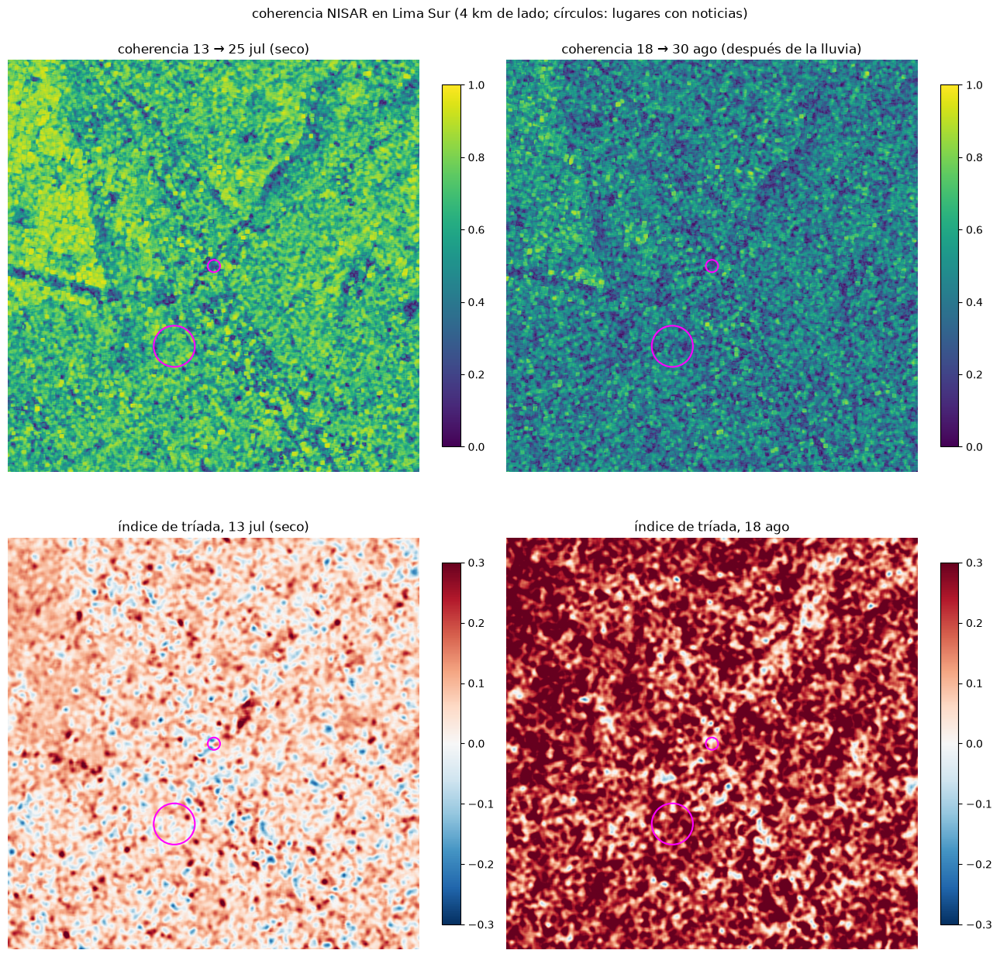

In [27]:
b = lugares_lima.iloc[0]
v = np.s_[b.fila - f0 - 400:b.fila - f0 + 400, b.col - c0 - 400:b.col - c0 + 400]
paneles = [(coh["13 jul (seco)"]["bc"], "coherencia 13 → 25 jul (seco)", "viridis", 0, 1),
           (coh["18 ago (lluvia del 16-17)"]["bc"], "coherencia 18 → 30 ago (después de la lluvia)", "viridis", 0, 1),
           (ndimage.uniform_filter(np.nan_to_num(indice["13 jul (seco)"]), 9), "índice de tríada, 13 jul (seco)", "RdBu_r", -0.3, 0.3),
           (ndimage.uniform_filter(np.nan_to_num(indice["18 ago (lluvia del 16-17)"]), 9), "índice de tríada, 18 ago", "RdBu_r", -0.3, 0.3)]
fig, ejes = plt.subplots(2, 2, figsize=(13, 13))
for ax, (img, titulo, cm, v0, v1) in zip(ejes.flat, paneles):
    im = ax.imshow(img[v], cmap=cm, vmin=v0, vmax=v1)
    for n in lugares_lima.itertuples():
        ax.add_patch(plt.Circle((n.col - b.col + 400, n.fila - b.fila + 400), max(n.radio_m, 60) / 5, fill=False, color="magenta", lw=1.5))
    ax.set_title(titulo)
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.04)
plt.suptitle("coherencia NISAR en Lima Sur (4 km de lado; círculos: lugares con noticias)")
plt.tight_layout()

## 7. Conclusiones

1. **Datos.** 22 pasadas NISAR RSLC (6 con lluvia y 16 días secos) de Lima, Tumbes y Arequipa, bajando solo el recorte de
   cada ciudad: unos 13 GB en total, cuando cada archivo completo pesa 4-28 GB. La geocodificación propia a 5 m con el DEM deja
   cada escena alineada con WorldCover; todas cubren la ciudad completa salvo Lima 14 ene (45 %, solo hay el cuadro sur).
2. **Etiqueta.** El umbral de Kittler-Illingworth (−12 a −15 dB) reproduce bien el agua permanente: recall 0.75-0.99 y
   falsa agua 2-7 % en las cinco escenas que sirven. Arequipa no se puede evaluar: casi no tiene agua permanente (7 638
   píxeles) y su AUC es 0.66. Pero el agua que la etiqueta marca en tierra (8-52 km² por escena) ya está oscura en los días
   secos en un 80-98 %: es arena, suelo desnudo y pozas de siempre. La etiqueta mide *superficie lisa y oscura*, no
   inundación.
3. **U-Net.** Los tres codificadores llegan a IoU 0.70-0.75 en validación (Lima 24 oct, otra pista y otra hora que el
   train); ResNet34 es el mejor (IoU 0.752, F1 0.859). En Tumbes, ciudad que no vio y con otro ancho de banda (40 MHz en vez
   de 20 MHz), logra IoU 0.811. El entrenamiento es inestable: el IoU de validación cae a casi 0 en épocas sueltas y la
   parada temprana corta en 6-8 épocas. Como la mejor época se elige con la validación, ese 0.75 es algo optimista; Tumbes
   es la medida independiente.
4. **Dónde acierta.** Casi todo el acierto está en el agua permanente: IoU 0.81 en Lima y 0.93 en Tumbes (mar, ríos y
   langostineras), contra 0.02 y 0.32 en la tierra a más de 200 m. En la tierra de Lima la U-Net casi no marca agua (0.09 %
   contra 1.4 % de la etiqueta). En Tumbes coincide en parte con lo que marca la etiqueta, pero eso ya estaba oscuro en los
   días secos (98 %).
5. **Agua de la lluvia.** Comparado con los días secos de la misma pista, el agua de lluvia de Tumbes (0.99 km²) y de
   Arequipa (0.01 km²) queda *por debajo* de lo que el mismo criterio marca en sus días secos (2.7-13.4 y 0.04-0.12 km²), y
   la de Lima 24 oct (0.26 km²) dentro del rango (0.08-4.9 km²). Solo dos lluvias de Lima, pista 083 (14 ene: 0.47 km²;
   18 ago: 0.75 km²), superan un poco el máximo de sus 7 días secos (0.45 km²), y en la figura son sobre todo franjas al
   borde del mar. No se puede afirmar que haya agua de lluvia detectable.
6. **Lugares de las noticias.** En Lima ningún lugar tiene agua ni un cambio de HH fuera del rango de los días secos. En
   Tumbes y Arequipa los lugares se oscurecen 1.0-2.0 dB, más que en cualquier día seco, pero entre el 8 % y el 35 % de las
   zonas urbanas de la misma ciudad bajó todavía más: se mojó la ciudad entera, no se ve agua empozada en esos puntos (y
   en esas dos ciudades solo hay dos días secos de referencia).
7. **Coherencia.** La lluvia del 16-17 ago sí deja huella en la fase: el índice de tríada urbano de Lima Sur sube a 0.25
   (0.07 en el día seco de control) y VMT José Gálvez está entre el 3 % de zonas que más coherencia perdieron (el baipás no
   destaca). Pero la caída cubre toda Lima Sur. El 5 oct, tres días después del aniego, la coherencia no se rompe (índice
   −0.19): lo que cambia es el 17 oct, un día "seco" con 1.2 mm de garúa en las 12 h previas según Open-Meteo. La coherencia
   ve la ciudad mojada, no el charco.
8. **En resumen.** Con NISAR en una sola polarización (HH) a 5 m, la U-Net segmenta bien el agua abierta grande (mar,
   ríos, pozas) y lo hace también en una ciudad que no vio. No alcanza para ver el agua de lluvia empozada en las calles:
   es poca, poco profunda, queda entre edificios y la pasada llega entre 13 h y 3 días después; en Lima, además, la garúa
   casi no distingue los días de lluvia de los secos (0-6 mm en 3 días en ambos). Harían falta pasadas más cercanas a la
   lluvia (la de Lima del 5 nov, horas después de los aniegos, cuando se publique), etiquetas de campo o de dron, la
   polarización HV y series de coherencia.